

# Relatório — Double K-Means no Spambase

## 1. Objetivo

Aplicar o **Double K-Means** ao conjunto de dados Spambase para encontrar:

* grupos de e-mails semelhantes;
* grupos de características semelhantes;
* características que diferenciam os grupos encontrados.

A base possui **4.601 e-mails e 57 variáveis**.

---

## 2. Padronização

Antes do agrupamento, os dados foram padronizados:

```r
Xs <- scale(X)
```

A padronização coloca as variáveis em uma escala comparável, evitando que uma variável tenha mais influência apenas porque possui valores numericamente maiores.

Após a padronização:

* média ≈ 0;
* desvio padrão ≈ 1.

---

## 3. Aplicação do Double K-Means

Foram testadas diferentes combinações de número de grupos de e-mails (`K`) e grupos de variáveis (`H`).

A solução escolhida foi:

```text
K = 2
H = 2
Silhueta = 0,6596
```

Isso significa que foram encontrados:

* **2 grupos de e-mails**;
* **2 grupos de variáveis**.

---

## 4. Resultado dos e-mails

Os 4.601 e-mails foram divididos em:

| Grupo   | Quantidade |
| ------- | ---------: |
| Grupo 1 |         34 |
| Grupo 2 |      4.567 |

O primeiro grupo é pequeno e apresenta características bastante diferentes do segundo.

---

## 5. Resultado das variáveis

As 57 variáveis foram divididas em:

* **46 variáveis** no primeiro grupo;
* **11 variáveis** no segundo grupo.

As 11 principais características foram:

```text
hp
hpl
labs
telnet
technology
85
650
857
415
lab
direct
```

Essas variáveis apresentaram valores muito maiores no grupo de 34 e-mails.

---

## 6. Comparação com Spam/Não-Spam

O grupo de 34 e-mails possui:

* **34 não-spam**
* **0 spam**

Já o grupo de 4.567 possui:

* **2.754 não-spam**
* **1.813 spam**

Portanto, o Double K-Means **não separou os e-mails simplesmente em spam e não-spam**.

O ARI encontrado foi:

```text
ARI = -0,0049
```

Isso indica pouca concordância entre os grupos encontrados e a classificação original.

---

## 7. Conclusão

O Double K-Means encontrou um pequeno grupo de **34 e-mails** com um padrão diferente, principalmente em **11 características**.

Essas 11 características foram as que mais diferenciaram os dois grupos.

Porém, o agrupamento não corresponde diretamente à classificação de spam e não-spam.

**Em resumo:**

> O algoritmo encontrou uma estrutura interna nos e-mails diferente da classificação original de spam.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/Projeto_emails_ML

/content/drive/MyDrive/Projeto_emails_ML


In [ ]:
!ls

data  double_kmeans_spambase.ipynb  double_kmeans_spambase.R  output


In [ ]:
!ls data

spambase.data  spambase.names


In [ ]:
import pandas as pd

arquivo = "/content/drive/MyDrive/Projeto_emails_ML/data/spambase.data"

df = pd.read_csv(arquivo, header=None)

print(df.shape)

(4601, 58)


In [ ]:
!ls -l

total 227
drwx------ 2 root root   4096 Oct  2 03:29 data
-rw------- 1 root root 193860 Oct  2 03:30 double_kmeans_spambase.ipynb
-rw------- 1 root root  29636 Oct  2 03:30 double_kmeans_spambase.R
drwx------ 2 root root   4096 Oct  2 03:30 output


In [ ]:
#Verificar o código real
!grep -n "melhor" double_kmeans_spambase.R

11:##     melhor execução segundo a FUNÇÃO OBJETIVO.
17:##  5. Para o melhor resultado com K*, mostra:
37:##  igual (ou melhor) que a do pacote.
139:##  Esta é a "função objetivo" do enunciado: quanto MAIOR f, melhor o ajuste.
147:##  por isso rodamos 100 inicializações aleatórias e ficamos com a melhor).
304:## 2.7  100 execuções para um par (K,H) e escolha da melhor
309:## isso permite ver se a melhor solução é encontrada com frequência (ótimo
311:dkm_melhor_de_n <- function(X, K, H, n_execucoes = 100, maxiter = 200, tol = 1e-6) {
315:  melhor <- NULL
320:    if (is.null(melhor) || res$f > melhor$f) melhor <- res   # guarda a de maior f
322:  melhor$f_todas <- f_todas
323:  melhor
384:  ## (a) 100 execuções; `res` já é a melhor segundo a função objetivo
385:  res <- dkm_melhor_de_n(Xs, K, H, n_execucoes = N_EXEC)
387:  ## (b) silhueta média da partição de objetos da melhor execução
394:  ## O que esperar: f praticamente IGUAL nos dois quando a melhor solução é
420:  f = r$res$f,     

In [ ]:
!grep -n "idx_star\|gradeH\|resf\|rH\|rf" double_kmeans_spambase.R

151:##                                               cujo perfil (linha de G V') está mais perto;
153:##                                               cujo perfil (coluna de U G) está mais perto;
203:## O "perfil" do cluster k de objetos, no espaço das J variáveis, é a linha
206:## quadrática  ||x_i - perfil_k||^2. Expandindo o quadrado:
207:##     ||x_i||^2  -  2 * x_i . perfil_k  +  ||perfil_k||^2
209:## - x_i . perfil_k = soma_h G[k,h] * (soma dos x_ij das variáveis do cluster h)
211:## - ||perfil_k||^2 = soma_h p_h * G[k,h]^2      (p_h = nº de variáveis do cluster h).
216:  prod_cruzado <- P %*% t(G)                      # n x K: x_i . perfil_k
217:  norma_perfil <- as.vector(G^2 %*% colSums(V))   # K   : ||perfil_k||^2
218:  ## D = distância ao perfil SEM o termo constante ||x_i||^2 (basta p/ decidir o arg min)
219:  D <- sweep(-2 * prod_cruzado, 2, norma_perfil, "+")
225:  ## objeto pior ajustado (maior distância ao seu próprio perfil) de um
243:## O perfil do cluster h de variáv

In [ ]:
!sed -n '175,300p' double_kmeans_spambase.R

## ---------------------------------------------------------------------
## G[k,h] = média de X no bloco (objetos do cluster k) x (variáveis do cluster h).
## Em notação matricial:
##      G = (U'U)^{-1}  U' X V  (V'V)^{-1}
##  - U' X V   (K x H) : SOMA dos valores de cada bloco;
##  - U'U e V'V são diagonais e contêm o TAMANHO de cada cluster, então
##    dividir por elas transforma soma em média. Como o número de células de
##    um bloco é (tamanho do cluster de objetos) x (tamanho do de variáveis),
##    usamos outer(tam_U, tam_V) para dividir.
calcula_G <- function(X, U, V) {
  soma_blocos <- t(U) %*% X %*% V
  soma_blocos / outer(colSums(U), colSums(V))
}

## ---------------------------------------------------------------------
## 2.3  Função objetivo f = tr(B'B) = ||B||^2
## ---------------------------------------------------------------------
## B = U G V' repete G[k,h] em todas as (n_k * p_h) células do bloco (k,h),
## logo  ||B||^2 = soma_{k,h} n_k * p_h * G[k,h]^2  (n_k = nº

In [ ]:
%load_ext rpy2.ipython

In [ ]:
!pip -q install rpy2

In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R

source("/content/drive/MyDrive/Projeto_emails_ML/double_kmeans_spambase.R")

n = 4601 objetos, J = 57 variáveis (1813 spam / 2788 não-spam)
K=2 H=1 | f=5742.00 (2.19% var.) | achada em 100/100 execuções | Sil=0.2961 | it=11 | f_drclust=NA
K=2 H=2 | f=17766.44 (6.78% var.) | achada em   7/100 execuções | Sil=0.6596 | it=29 | f_drclust=NA
K=3 H=1 | f=7841.28 (2.99% var.) | achada em 100/100 execuções | Sil=0.2515 | it=40 | f_drclust=NA
K=3 H=2 | f=22878.37 (8.73% var.) | achada em   7/100 execuções | Sil=0.2454 | it=51 | f_drclust=NA
K=3 H=3 | f=27817.15 (10.61% var.) | achada em  15/100 execuções | Sil=0.1426 | it=19 | f_drclust=NA
K=4 H=1 | f=8976.37 (3.42% var.) | achada em 100/100 execuções | Sil=0.0484 | it=38 | f_drclust=NA
K=4 H=2 | f=28892.02 (11.02% var.) | achada em  53/100 execuções | Sil=0.2428 | it=28 | f_drclust=NA
K=4 H=3 | f=33733.22 (12.87% var.) | achada em  18/100 execuções | Sil=0.1620 | it=41 | f_drclust=NA
K=4 H=4 | f=34987.65 (13.34% var.) | achada em   1/100 execuções | Sil=0.1585 | it=26 | f_drclust=NA

== Resumo por par (K,H) ==
 K H    

In [ ]:
%%R

# ============================================================
# 1. LER A BASE
# ============================================================

caminho <- "/content/drive/MyDrive/Projeto_emails_ML/data/spambase.data"

dados <- read.csv(
  caminho,
  header = FALSE
)

cat("Dimensão da base:\n")
print(dim(dados))


# ============================================================
# 2. SEPARAR X E y
# ============================================================

# As primeiras 57 colunas são as variáveis
# A última coluna é o rótulo:
# 0 = não-spam
# 1 = spam

X <- as.matrix(dados[, 1:57])
y <- as.numeric(dados[, 58])


# ============================================================
# 3. MOSTRAR INFORMAÇÕES SOBRE X E y
# ============================================================

cat("\nNúmero de objetos (n):", nrow(X), "\n")
cat("Número de variáveis (J):", ncol(X), "\n")

cat("\nQuantidade de NÃO-SPAM (0):",
    sum(y == 0), "\n")

cat("Quantidade de SPAM (1):",
    sum(y == 1), "\n")


# ============================================================
# 4. MOSTRAR UM PEQUENO EXEMPLO DE X
# ============================================================

cat("\nPrimeiras 5 linhas de X:\n")
print(X[1:5, 1:10])


# ============================================================
# 5. PADRONIZAÇÃO
# ============================================================

Xs <- scale(X)


# ============================================================
# 6. MOSTRAR O RESULTADO DA PADRONIZAÇÃO
# ============================================================

cat("\nPrimeiras 5 linhas de Xs:\n")
print(Xs[1:5, 1:10])


# ============================================================
# 7. VERIFICAR MÉDIA E DESVIO PADRÃO
# ============================================================

cat("\nMédia aproximada da primeira variável após escala:\n")
print(mean(Xs[,1]))

cat("\nDesvio padrão aproximado da primeira variável após escala:\n")
print(sd(Xs[,1]))

Dimensão da base:
[1] 4601   58

Número de objetos (n): 4601 
Número de variáveis (J): 57 

Quantidade de NÃO-SPAM (0): 2788 
Quantidade de SPAM (1): 1813 

Primeiras 5 linhas de X:
       V1   V2   V3 V4   V5   V6   V7   V8   V9  V10
[1,] 0.00 0.64 0.64  0 0.32 0.00 0.00 0.00 0.00 0.00
[2,] 0.21 0.28 0.50  0 0.14 0.28 0.21 0.07 0.00 0.94
[3,] 0.06 0.00 0.71  0 1.23 0.19 0.19 0.12 0.64 0.25
[4,] 0.00 0.00 0.00  0 0.63 0.00 0.31 0.63 0.31 0.63
[5,] 0.00 0.00 0.00  0 0.63 0.00 0.31 0.63 0.31 0.63

Primeiras 5 linhas de Xs:
             V1          V2         V3          V4          V5         V6
[1,] -0.3423965  0.33084894  0.7127813 -0.04689449  0.01156345 -0.3502281
[2,]  0.3453219  0.05190355  0.4350823 -0.04689449 -0.25608946  0.6723262
[3,] -0.1459055 -0.16505397  0.8516308 -0.04689449  1.36469761  0.3436480
[4,] -0.3423965 -0.16505397 -0.5567001 -0.04689449  0.47252124 -0.3502281
[5,] -0.3423965 -0.16505397 -0.5567001 -0.04689449  0.47252124 -0.3502281
             V7          V8  

In [ ]:
%%R

# ============================================================
# INVESTIGAÇÃO DOS CLUSTERS
# ============================================================

# Recupera os clusters encontrados pelo Double K-Means
cl <- cl_star

cat("Tamanho dos clusters:\n")
print(table(cl))


# ------------------------------------------------------------
# 1. Cruzamento cluster x classe verdadeira
# ------------------------------------------------------------

cat("\nTabela Cluster x classe verdadeira:\n")

tab <- table(
  Cluster = cl,
  Classe = y
)

print(tab)


# ------------------------------------------------------------
# 2. Proporção de spam dentro de cada cluster
# ------------------------------------------------------------

cat("\nProporção de spam em cada cluster:\n")

prop_spam <- tapply(y == 1, cl, mean)

print(prop_spam)


# ------------------------------------------------------------
# 3. Proporção de não-spam em cada cluster
# ------------------------------------------------------------

cat("\nProporção de não-spam em cada cluster:\n")

prop_naospam <- tapply(y == 0, cl, mean)

print(prop_naospam)


# ------------------------------------------------------------
# 4. Comparar tamanho dos clusters com tamanho real das classes
# ------------------------------------------------------------

cat("\nProporção de objetos em cada cluster:\n")

prop_cluster <- prop.table(table(cl))

print(prop_cluster)


cat("\nProporção real das classes:\n")

print(prop.table(table(y)))

Tamanho dos clusters:
cl
   1    2 
  34 4567 

Tabela Cluster x classe verdadeira:
       Classe
Cluster    0    1
      1   34    0
      2 2754 1813

Proporção de spam em cada cluster:
        1         2 
0.0000000 0.3969783 

Proporção de não-spam em cada cluster:
        1         2 
1.0000000 0.6030217 

Proporção de objetos em cada cluster:
cl
          1           2 
0.007389698 0.992610302 

Proporção real das classes:
y
        0         1 
0.6059552 0.3940448 


In [ ]:
%%R

# ============================================================
# INVESTIGAÇÃO DO CLUSTER 1
# ============================================================

# 1. Quantidade de elementos em cada cluster
cat("Tamanho dos clusters:\n")
print(table(cl))

# 2. Índices dos elementos que estão no Cluster 1
indices_c1 <- which(cl == 1)

cat("\nQuantidade de elementos no Cluster 1:\n")
print(length(indices_c1))

cat("\nPrimeiros índices do Cluster 1:\n")
print(head(indices_c1, 20))

# 3. Classes verdadeiras desses elementos
cat("\nClasses verdadeiras dos elementos do Cluster 1:\n")
print(table(y[indices_c1]))

# 4. Proporção das classes dentro do Cluster 1
cat("\nProporção das classes dentro do Cluster 1:\n")
print(prop.table(table(y[indices_c1])))

# 5. Comparar médias das variáveis:
#    Cluster 1 x Cluster 2
media_c1 <- colMeans(X[cl == 1, , drop = FALSE])
media_c2 <- colMeans(X[cl == 2, , drop = FALSE])

comparacao <- data.frame(
  variavel = colnames(X),
  media_cluster1 = media_c1,
  media_cluster2 = media_c2,
  diferenca = media_c1 - media_c2
)

# Ordenar pelas maiores diferenças absolutas
comparacao <- comparacao[
  order(abs(comparacao$diferenca), decreasing = TRUE),
]

cat("\nVariáveis que mais diferenciam os dois clusters:\n")
print(head(comparacao, 15))

Tamanho dos clusters:
cl
   1    2 
  34 4567 

Quantidade de elementos no Cluster 1:
[1] 34

Primeiros índices do Cluster 1:
 [1] 1819 1879 1923 1965 2054 2151 2271 2328 2555 2575 2631 2674 2697 2849 2916
[16] 2975 3020 3021 3158 3246

Classes verdadeiras dos elementos do Cluster 1:

 0 
34 

Proporção das classes dentro do Cluster 1:

0 
1 

Variáveis que mais diferenciam os dois clusters:
    variavel media_cluster1 media_cluster2   diferenca
V57      V57      37.794118   285.11692577 -247.322808
V56      V56      10.970588    52.47952704  -41.508939
V25      V25       6.697941     0.50373111    6.194210
V30      V30       3.392353     0.07836216    3.313991
V31      V31       3.333529     0.04041822    3.293111
V36      V36       3.333529     0.07338515    3.260144
V35      V35       3.333529     0.08137946    3.252150
V28      V28       3.333529     0.10095686    3.232573
V32      V32       3.170294     0.02379680    3.146497
V34      V34       3.170294     0.02458945    3.145705


In [ ]:
%%R

# Mostrar os nomes originais das 57 variáveis
cat("Nomes das variáveis:\n\n")

for (j in 1:ncol(X)) {
  cat(j, "=", colnames(X)[j], "\n")
}

Nomes das variáveis:

1 = V1 
2 = V2 
3 = V3 
4 = V4 
5 = V5 
6 = V6 
7 = V7 
8 = V8 
9 = V9 
10 = V10 
11 = V11 
12 = V12 
13 = V13 
14 = V14 
15 = V15 
16 = V16 
17 = V17 
18 = V18 
19 = V19 
20 = V20 
21 = V21 
22 = V22 
23 = V23 
24 = V24 
25 = V25 
26 = V26 
27 = V27 
28 = V28 
29 = V29 
30 = V30 
31 = V31 
32 = V32 
33 = V33 
34 = V34 
35 = V35 
36 = V36 
37 = V37 
38 = V38 
39 = V39 
40 = V40 
41 = V41 
42 = V42 
43 = V43 
44 = V44 
45 = V45 
46 = V46 
47 = V47 
48 = V48 
49 = V49 
50 = V50 
51 = V51 
52 = V52 
53 = V53 
54 = V54 
55 = V55 
56 = V56 
57 = V57 


In [ ]:
%%R

arquivo_names <- "/content/drive/MyDrive/Projeto_emails_ML/data/spambase.names"

cat(readLines(arquivo_names), sep = "\n")

| SPAM E-MAIL DATABASE ATTRIBUTES (in .names format)
|
| 48 continuous real [0,100] attributes of type word_freq_WORD 
| = percentage of words in the e-mail that match WORD,
| i.e. 100 * (number of times the WORD appears in the e-mail) / 
| total number of words in e-mail.  A "word" in this case is any 
| string of alphanumeric characters bounded by non-alphanumeric 
| characters or end-of-string.
|
| 6 continuous real [0,100] attributes of type char_freq_CHAR
| = percentage of characters in the e-mail that match CHAR,
| i.e. 100 * (number of CHAR occurences) / total characters in e-mail
|
| 1 continuous real [1,...] attribute of type capital_run_length_average
| = average length of uninterrupted sequences of capital letters
|
| 1 continuous integer [1,...] attribute of type capital_run_length_longest
| = length of longest uninterrupted sequence of capital letters
|
| 1 continuous integer [1,...] attribute of type capital_run_length_total
| = sum of length of uninterrupted sequences of

In [ ]:
%%R

# ============================================================
# INVESTIGAÇÃO DOS CLUSTERS
# ============================================================

# Nomes reais das 57 variáveis
nomes_variaveis <- c(
  "word_freq_make",
  "word_freq_address",
  "word_freq_all",
  "word_freq_3d",
  "word_freq_our",
  "word_freq_over",
  "word_freq_remove",
  "word_freq_internet",
  "word_freq_order",
  "word_freq_mail",
  "word_freq_receive",
  "word_freq_will",
  "word_freq_people",
  "word_freq_report",
  "word_freq_addresses",
  "word_freq_free",
  "word_freq_business",
  "word_freq_email",
  "word_freq_you",
  "word_freq_credit",
  "word_freq_your",
  "word_freq_font",
  "word_freq_000",
  "word_freq_money",
  "word_freq_hp",
  "word_freq_hpl",
  "word_freq_george",
  "word_freq_650",
  "word_freq_lab",
  "word_freq_labs",
  "word_freq_telnet",
  "word_freq_857",
  "word_freq_data",
  "word_freq_415",
  "word_freq_85",
  "word_freq_technology",
  "word_freq_1999",
  "word_freq_parts",
  "word_freq_pm",
  "word_freq_direct",
  "word_freq_cs",
  "word_freq_meeting",
  "word_freq_original",
  "word_freq_project",
  "word_freq_re",
  "word_freq_edu",
  "word_freq_table",
  "word_freq_conference",
  "char_freq_;",
  "char_freq_(",
  "char_freq_[",
  "char_freq_!",
  "char_freq_$",
  "char_freq_#",
  "capital_run_length_average",
  "capital_run_length_longest",
  "capital_run_length_total"
)

# ============================================================
# MÉDIA DAS VARIÁVEIS EM CADA CLUSTER
# ============================================================

media_1 <- colMeans(X[cl == 1, ])
media_2 <- colMeans(X[cl == 2, ])

investigacao <- data.frame(
  variavel = nomes_variaveis,
  cluster_1 = media_1,
  cluster_2 = media_2
)

# diferença entre as médias
investigacao$diferenca <- investigacao$cluster_1 -
                          investigacao$cluster_2

# ordenar pela maior diferença absoluta
investigacao <- investigacao[
  order(abs(investigacao$diferenca), decreasing = TRUE),
]

cat("\n========================================\n")
cat("VARIÁVEIS QUE MAIS DIFERENCIAM OS CLUSTERS\n")
cat("========================================\n\n")

print(head(investigacao, 20), row.names = FALSE)


VARIÁVEIS QUE MAIS DIFERENCIAM OS CLUSTERS

                   variavel  cluster_1    cluster_2    diferenca
   capital_run_length_total 37.7941176 285.11692577 -247.3228081
 capital_run_length_longest 10.9705882  52.47952704  -41.5089388
               word_freq_hp  6.6979412   0.50373111    6.1942101
             word_freq_labs  3.3923529   0.07836216    3.3139908
           word_freq_telnet  3.3335294   0.04041822    3.2931112
       word_freq_technology  3.3335294   0.07338515    3.2601443
               word_freq_85  3.3335294   0.08137946    3.2521500
              word_freq_650  3.3335294   0.10095686    3.2325725
              word_freq_857  3.1702941   0.02379680    3.1464973
              word_freq_415  3.1702941   0.02458945    3.1457047
              word_freq_lab  3.2052941   0.07578936    3.1295048
              word_freq_hpl  3.3335294   0.24254215    3.0909873
           word_freq_direct  3.1235294   0.04206262    3.0814668
           word_freq_george  3.1235294   0.74

In [ ]:
%%R

cat("\n========================================\n")
cat("ANÁLISE DO CLUSTER 1\n")
cat("========================================\n\n")

indices_c1 <- which(cl == 1)

cat("Quantidade de elementos:", length(indices_c1), "\n\n")

cat("Índices dos elementos:\n")
print(indices_c1)

cat("\nClasses verdadeiras:\n")
print(table(y[indices_c1]))

cat("\nProporção das classes:\n")
print(prop.table(table(y[indices_c1])))


ANÁLISE DO CLUSTER 1

Quantidade de elementos: 34 

Índices dos elementos:
 [1] 1819 1879 1923 1965 2054 2151 2271 2328 2555 2575 2631 2674 2697 2849 2916
[16] 2975 3020 3021 3158 3246 3273 3304 3364 3424 3491 3532 3562 3563 3856 3880
[31] 3920 4020 4021 4040

Classes verdadeiras:

 0 
34 

Proporção das classes:

0 
1 


In [ ]:
%%R

cat("\n========================================\n")
cat("COMPARAÇÃO DOS NÃO-SPAMS\n")
cat("========================================\n\n")

nao_spam_c1 <- which(cl == 1 & y == 0)
nao_spam_c2 <- which(cl == 2 & y == 0)

cat("Não-spam no Cluster 1:", length(nao_spam_c1), "\n")
cat("Não-spam no Cluster 2:", length(nao_spam_c2), "\n")


COMPARAÇÃO DOS NÃO-SPAMS

Não-spam no Cluster 1: 34 
Não-spam no Cluster 2: 2754 


In [ ]:
%%R

# ============================================================
# COMPARAÇÃO DOS NÃO-SPAMS
# CLUSTER 1 x CLUSTER 2
# ============================================================

media_ns_c1 <- colMeans(X[nao_spam_c1, ])
media_ns_c2 <- colMeans(X[nao_spam_c2, ])

comparacao_ns <- data.frame(
  variavel = nomes_variaveis,
  cluster_1 = media_ns_c1,
  cluster_2 = media_ns_c2
)

comparacao_ns$diferenca <-
  comparacao_ns$cluster_1 - comparacao_ns$cluster_2

# Ordenar pela maior diferença absoluta
comparacao_ns <- comparacao_ns[
  order(abs(comparacao_ns$diferenca), decreasing = TRUE),
]

cat("\n========================================\n")
cat("NÃO-SPAMS: CLUSTER 1 vs CLUSTER 2\n")
cat("========================================\n\n")

print(
  head(comparacao_ns, 20),
  row.names = FALSE
)


NÃO-SPAMS: CLUSTER 1 vs CLUSTER 2

                   variavel  cluster_1    cluster_2    diferenca
   capital_run_length_total 37.7941176 162.99782135 -125.2037037
 capital_run_length_longest 10.9705882  18.30392157   -7.3333333
               word_freq_hp  6.6979412   0.82383805    5.8741031
           word_freq_telnet  3.3335294   0.06618736    3.2673420
             word_freq_labs  3.3923529   0.12602033    3.2663326
       word_freq_technology  3.3335294   0.10226580    3.2312636
               word_freq_85  3.3335294   0.13039216    3.2031373
              word_freq_650  3.3335294   0.15504357    3.1784858
              word_freq_857  3.1702941   0.03912128    3.1311728
              word_freq_415  3.1702941   0.03960784    3.1306863
              word_freq_lab  3.2052941   0.12523239    3.0800617
           word_freq_direct  3.1235294   0.04558097    3.0779484
              word_freq_hpl  3.3335294   0.39617284    2.9373566
           word_freq_george  3.1235294   1.24232389   

In [ ]:
%%R

cat("Média das variáveis:\n")

print(
  round(
    colMeans(Xs),
    2
  )
)

cat("\nDesvio padrão das variáveis:\n")

print(
  round(
    apply(Xs, 2, sd),
    2
  )
)

Média das variáveis:
 V1  V2  V3  V4  V5  V6  V7  V8  V9 V10 V11 V12 V13 V14 V15 V16 V17 V18 V19 V20 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
V21 V22 V23 V24 V25 V26 V27 V28 V29 V30 V31 V32 V33 V34 V35 V36 V37 V38 V39 V40 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 
V41 V42 V43 V44 V45 V46 V47 V48 V49 V50 V51 V52 V53 V54 V55 V56 V57 
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 

Desvio padrão das variáveis:
 V1  V2  V3  V4  V5  V6  V7  V8  V9 V10 V11 V12 V13 V14 V15 V16 V17 V18 V19 V20 
  1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1 
V21 V22 V23 V24 V25 V26 V27 V28 V29 V30 V31 V32 V33 V34 V35 V36 V37 V38 V39 V40 
  1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1 
V41 V42 V43 V44 V45 V46 V47 V48 V49 V50 V51 V52 V53 V54 V55 V56 V57 
  1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1   1 


In [ ]:
%%R

cat("========================================\n")
cat("NOMES DAS COLUNAS DE X\n")
cat("========================================\n\n")

print(colnames(X))

NOMES DAS COLUNAS DE X

 [1] "V1"  "V2"  "V3"  "V4"  "V5"  "V6"  "V7"  "V8"  "V9"  "V10" "V11" "V12"
[13] "V13" "V14" "V15" "V16" "V17" "V18" "V19" "V20" "V21" "V22" "V23" "V24"
[25] "V25" "V26" "V27" "V28" "V29" "V30" "V31" "V32" "V33" "V34" "V35" "V36"
[37] "V37" "V38" "V39" "V40" "V41" "V42" "V43" "V44" "V45" "V46" "V47" "V48"
[49] "V49" "V50" "V51" "V52" "V53" "V54" "V55" "V56" "V57"


In [ ]:
%%R

principais <- c(
  "word_freq_hp",
  "word_freq_hpl",
  "word_freq_labs",
  "word_freq_telnet",
  "word_freq_technology",
  "word_freq_85",
  "word_freq_650",
  "word_freq_857",
  "word_freq_415",
  "word_freq_lab",
  "word_freq_direct"
)

cat("========================================\n")
cat("VARIÁVEIS QUE EXISTEM EM X\n")
cat("========================================\n\n")

print(principais[principais %in% colnames(X)])

cat("\n========================================\n")
cat("VARIÁVEIS QUE NÃO EXISTEM EM X\n")
cat("========================================\n\n")

print(principais[!principais %in% colnames(X)])

VARIÁVEIS QUE EXISTEM EM X

character(0)

VARIÁVEIS QUE NÃO EXISTEM EM X

 [1] "word_freq_hp"         "word_freq_hpl"        "word_freq_labs"      
 [4] "word_freq_telnet"     "word_freq_technology" "word_freq_85"        
 [7] "word_freq_650"        "word_freq_857"        "word_freq_415"       
[10] "word_freq_lab"        "word_freq_direct"    


In [ ]:
%%R

cat("Número de colunas de X:", ncol(X), "\n")
cat("Número de linhas de X:", nrow(X), "\n")

cat("\nPrimeiras 10 colunas de X:\n")
print(X[, 1:10])

Número de colunas de X: 57 
Número de linhas de X: 4601 

Primeiras 10 colunas de X:
          V1    V2   V3    V4    V5   V6   V7    V8   V9   V10
   [1,] 0.00  0.64 0.64  0.00  0.32 0.00 0.00  0.00 0.00  0.00
   [2,] 0.21  0.28 0.50  0.00  0.14 0.28 0.21  0.07 0.00  0.94
   [3,] 0.06  0.00 0.71  0.00  1.23 0.19 0.19  0.12 0.64  0.25
   [4,] 0.00  0.00 0.00  0.00  0.63 0.00 0.31  0.63 0.31  0.63
   [5,] 0.00  0.00 0.00  0.00  0.63 0.00 0.31  0.63 0.31  0.63
   [6,] 0.00  0.00 0.00  0.00  1.85 0.00 0.00  1.85 0.00  0.00
   [7,] 0.00  0.00 0.00  0.00  1.92 0.00 0.00  0.00 0.00  0.64
   [8,] 0.00  0.00 0.00  0.00  1.88 0.00 0.00  1.88 0.00  0.00
   [9,] 0.15  0.00 0.46  0.00  0.61 0.00 0.30  0.00 0.92  0.76
  [10,] 0.06  0.12 0.77  0.00  0.19 0.32 0.38  0.00 0.06  0.00
  [11,] 0.00  0.00 0.00  0.00  0.00 0.00 0.96  0.00 0.00  1.92
  [12,] 0.00  0.00 0.25  0.00  0.38 0.25 0.25  0.00 0.00  0.00
  [13,] 0.00  0.69 0.34  0.00  0.34 0.00 0.00  0.00 0.00  0.00
  [14,] 0.00  0.00 0.00  0.00  0.

In [ ]:
%%R

nomes_spambase <- c(
  "word_freq_make",
  "word_freq_address",
  "word_freq_all",
  "word_freq_3d",
  "word_freq_our",
  "word_freq_over",
  "word_freq_remove",
  "word_freq_internet",
  "word_freq_order",
  "word_freq_mail",
  "word_freq_receive",
  "word_freq_will",
  "word_freq_people",
  "word_freq_report",
  "word_freq_addresses",
  "word_freq_free",
  "word_freq_business",
  "word_freq_email",
  "word_freq_you",
  "word_freq_credit",
  "word_freq_your",
  "word_freq_font",
  "word_freq_000",
  "word_freq_money",
  "word_freq_hp",
  "word_freq_hpl",
  "word_freq_george",
  "word_freq_650",
  "word_freq_lab",
  "word_freq_labs",
  "word_freq_telnet",
  "word_freq_857",
  "word_freq_data",
  "word_freq_415",
  "word_freq_85",
  "word_freq_technology",
  "word_freq_1999",
  "word_freq_parts",
  "word_freq_pm",
  "word_freq_direct",
  "word_freq_cs",
  "word_freq_meeting",
  "word_freq_original",
  "word_freq_project",
  "word_freq_re",
  "word_freq_edu",
  "word_freq_table",
  "word_freq_conference",
  "char_freq_;",
  "char_freq_(",
  "char_freq_[",
  "char_freq_!",
  "char_freq_$",
  "char_freq_#",
  "capital_run_length_average",
  "capital_run_length_longest",
  "capital_run_length_total"
)

colnames(X) <- nomes_spambase

cat("Nomes atribuídos:", ncol(colnames(X)), "\n")

print(colnames(X))

VARIÁVEIS QUE EXISTEM EM X

character(0)

VARIÁVEIS QUE NÃO EXISTEM EM X

 [1] "word_freq_hp"         "word_freq_hpl"        "word_freq_labs"      
 [4] "word_freq_telnet"     "word_freq_technology" "word_freq_85"        
 [7] "word_freq_650"        "word_freq_857"        "word_freq_415"       
[10] "word_freq_lab"        "word_freq_direct"    


In [ ]:
%%R

# ============================================================
# VERIFICAR AS 11 VARIÁVEIS DO GRUPO 2 NO CLUSTER 1
# ============================================================

# Posições das 11 variáveis
posicoes <- c(25, 26, 30, 31, 36, 35, 28, 32, 34, 29, 40)

# Nomes apenas para facilitar a leitura do resultado
nomes_variaveis <- c(
  "word_freq_hp",
  "word_freq_hpl",
  "word_freq_labs",
  "word_freq_telnet",
  "word_freq_technology",
  "word_freq_85",
  "word_freq_650",
  "word_freq_857",
  "word_freq_415",
  "word_freq_lab",
  "word_freq_direct"
)

# Selecionar as 34 observações do Cluster 1
# e as 11 variáveis pelas posições
dados_c1 <- X[cl == 1, posicoes, drop = FALSE]

# Colocar nomes somente no resultado
colnames(dados_c1) <- nomes_variaveis


cat("\n========================================\n")
cat("MÉDIAS NO CLUSTER 1\n")
cat("========================================\n\n")

print(round(colMeans(dados_c1), 3))


cat("\n========================================\n")
cat("MÍNIMOS NO CLUSTER 1\n")
cat("========================================\n\n")

print(round(apply(dados_c1, 2, min), 3))


cat("\n========================================\n")
cat("MÁXIMOS NO CLUSTER 1\n")
cat("========================================\n\n")

print(round(apply(dados_c1, 2, max), 3))


MÉDIAS NO CLUSTER 1

        word_freq_hp        word_freq_hpl       word_freq_labs 
               6.698                3.334                3.392 
    word_freq_telnet word_freq_technology         word_freq_85 
               3.334                3.334                3.334 
       word_freq_650        word_freq_857        word_freq_415 
               3.334                3.170                3.170 
       word_freq_lab     word_freq_direct 
               3.205                3.124 

MÍNIMOS NO CLUSTER 1

        word_freq_hp        word_freq_hpl       word_freq_labs 
                1.58                 1.58                 1.58 
    word_freq_telnet word_freq_technology         word_freq_85 
                1.58                 1.58                 1.58 
       word_freq_650        word_freq_857        word_freq_415 
                1.58                 0.00                 0.00 
       word_freq_lab     word_freq_direct 
                0.00                 0.00 

MÁXIMOS NO CLU

In [ ]:
%%R

cat("\n========================================\n")
cat("QUARTIS DO CLUSTER 1\n")
cat("========================================\n\n")

for (i in 1:ncol(dados_c1)) {

  cat("\n----------------------------------------\n")
  cat(colnames(dados_c1)[i], "\n")
  cat("----------------------------------------\n")

  valores <- dados_c1[, i]

  print(
    round(
      quantile(
        valores,
        probs = c(0, 0.25, 0.50, 0.75, 1),
        na.rm = TRUE
      ),
      3
    )
  )
}


QUARTIS DO CLUSTER 1


----------------------------------------
word_freq_hp 
----------------------------------------
  0%  25%  50%  75% 100% 
1.58 4.65 7.14 8.69 9.52 

----------------------------------------
word_freq_hpl 
----------------------------------------
   0%   25%   50%   75%  100% 
1.580 2.283 3.570 4.340 4.760 

----------------------------------------
word_freq_labs 
----------------------------------------
  0%  25%  50%  75% 100% 
1.58 2.32 3.57 4.34 4.76 

----------------------------------------
word_freq_telnet 
----------------------------------------
   0%   25%   50%   75%  100% 
1.580 2.283 3.570 4.340 4.760 

----------------------------------------
word_freq_technology 
----------------------------------------
   0%   25%   50%   75%  100% 
1.580 2.283 3.570 4.340 4.760 

----------------------------------------
word_freq_85 
----------------------------------------
   0%   25%   50%   75%  100% 
1.580 2.283 3.570 4.340 4.760 

---------------------------

In [ ]:
%%R

# ============================================================
# PERFIL INDIVIDUAL DOS 34 E-MAILS DO CLUSTER 1
# ============================================================

# Mediana de cada uma das 11 variáveis
medianas <- apply(dados_c1, 2, median, na.rm = TRUE)

# Para cada e-mail:
# TRUE  = valor >= mediana
# FALSE = valor < mediana
acima_mediana <- sweep(
  dados_c1,
  2,
  medianas,
  FUN = ">="
)

# Quantas das 11 variáveis estão acima da mediana
qtd_acima <- rowSums(acima_mediana)

cat("\n========================================\n")
cat("QUANTIDADE DE VARIÁVEIS ACIMA DA MEDIANA\n")
cat("========================================\n\n")

print(table(qtd_acima))


cat("\n========================================\n")
cat("RESUMO\n")
cat("========================================\n\n")

cat("Número de e-mails:", nrow(dados_c1), "\n")
cat("Número de variáveis analisadas:", ncol(dados_c1), "\n")
cat("Mínimo de variáveis acima da mediana:",
    min(qtd_acima), "\n")
cat("Máximo de variáveis acima da mediana:",
    max(qtd_acima), "\n")
cat("Média de variáveis acima da mediana:",
    round(mean(qtd_acima), 2), "\n")
cat("Mediana da quantidade:",
    median(qtd_acima), "\n")


QUANTIDADE DE VARIÁVEIS ACIMA DA MEDIANA

qtd_acima
 0  1  2  7 11 
11  4  1  2 16 

RESUMO

Número de e-mails: 34 
Número de variáveis analisadas: 11 
Mínimo de variáveis acima da mediana: 0 
Máximo de variáveis acima da mediana: 11 
Média de variáveis acima da mediana: 5.76 
Mediana da quantidade: 7 


In [ ]:
%%R

# ============================================================
# COMPARAÇÃO DAS MEDIANAS:
# CLUSTER 1 × CLUSTER 2
# ============================================================

dados_c2 <- X[cl == 2, posicoes, drop = FALSE]

colnames(dados_c2) <- nomes_variaveis

med_c1 <- apply(dados_c1, 2, median, na.rm = TRUE)
med_c2 <- apply(dados_c2, 2, median, na.rm = TRUE)

comparacao_medianas <- data.frame(
  Variavel = nomes_variaveis,
  Mediana_Cluster_1 = med_c1,
  Mediana_Cluster_2 = med_c2,
  Diferenca = med_c1 - med_c2
)

comparacao_medianas <- comparacao_medianas[
  order(-abs(comparacao_medianas$Diferenca)),
]

print(
  data.frame(
    Variavel = comparacao_medianas$Variavel,
    Mediana_Cluster_1 = round(comparacao_medianas$Mediana_Cluster_1, 3),
    Mediana_Cluster_2 = round(comparacao_medianas$Mediana_Cluster_2, 3),
    Diferenca = round(comparacao_medianas$Diferenca, 3)
  ),
  row.names = FALSE
)

             Variavel Mediana_Cluster_1 Mediana_Cluster_2 Diferenca
         word_freq_hp             7.140                 0     7.140
        word_freq_hpl             3.570                 0     3.570
       word_freq_labs             3.570                 0     3.570
     word_freq_telnet             3.570                 0     3.570
 word_freq_technology             3.570                 0     3.570
         word_freq_85             3.570                 0     3.570
        word_freq_650             3.570                 0     3.570
        word_freq_lab             3.345                 0     3.345
        word_freq_857             3.145                 0     3.145
        word_freq_415             3.145                 0     3.145
     word_freq_direct             3.075                 0     3.075


In [ ]:
%%R

# ============================================================
# VALORES ORIGINAIS DAS 11 VARIÁVEIS NO CLUSTER 1
# ============================================================

resumo_c1_original <- data.frame(
  Variavel = nomes_variaveis,
  Minimo = apply(dados_c1, 2, min, na.rm = TRUE),
  Q1 = apply(dados_c1, 2, quantile, probs = 0.25, na.rm = TRUE),
  Mediana = apply(dados_c1, 2, median, na.rm = TRUE),
  Q3 = apply(dados_c1, 2, quantile, probs = 0.75, na.rm = TRUE),
  Maximo = apply(dados_c1, 2, max, na.rm = TRUE)
)

print(
  data.frame(
    Variavel = resumo_c1_original$Variavel,
    Minimo = round(resumo_c1_original$Minimo, 3),
    Q1 = round(resumo_c1_original$Q1, 3),
    Mediana = round(resumo_c1_original$Mediana, 3),
    Q3 = round(resumo_c1_original$Q3, 3),
    Maximo = round(resumo_c1_original$Maximo, 3)
  ),
  row.names = FALSE
)

             Variavel Minimo    Q1 Mediana   Q3 Maximo
         word_freq_hp   1.58 4.650   7.140 8.69   9.52
        word_freq_hpl   1.58 2.283   3.570 4.34   4.76
       word_freq_labs   1.58 2.320   3.570 4.34   4.76
     word_freq_telnet   1.58 2.283   3.570 4.34   4.76
 word_freq_technology   1.58 2.283   3.570 4.34   4.76
         word_freq_85   1.58 2.283   3.570 4.34   4.76
        word_freq_650   1.58 2.283   3.570 4.34   4.76
        word_freq_857   0.00 2.232   3.145 4.34   4.76
        word_freq_415   0.00 2.232   3.145 4.34   4.76
        word_freq_lab   0.00 2.085   3.345 4.34   5.55
     word_freq_direct   0.00 2.085   3.075 4.34   4.76


O Cluster 1 é caracterizado principalmente por:

word_freq_hp

word_freq_hpl

word_freq_labs

word_freq_telnet

word_freq_technology

word_freq_85

word_freq_650

word_freq_857

word_freq_415

word_freq_lab

word_freq_direct

E essas variáveis apresentam valores muito maiores no Cluster 1 do que no Cluster 2.

In [ ]:
%%R

# ============================================================
# COMPARAÇÃO DAS 57 VARIÁVEIS
# CLUSTER 1 × CLUSTER 2
# ============================================================

# Medianas das 57 variáveis
medianas_c1_57 <- apply(X[cl == 1, , drop = FALSE], 2, median, na.rm = TRUE)
medianas_c2_57 <- apply(X[cl == 2, , drop = FALSE], 2, median, na.rm = TRUE)

# Diferença entre as medianas
diferenca_57 <- medianas_c1_57 - medianas_c2_57

# Criar tabela
comparacao_57 <- data.frame(
  Posicao = 1:ncol(X),
  Mediana_C1 = medianas_c1_57,
  Mediana_C2 = medianas_c2_57,
  Diferenca = diferenca_57,
  Diferenca_Absoluta = abs(diferenca_57)
)

# Ordenar da maior diferença para a menor
comparacao_57 <- comparacao_57[
  order(-comparacao_57$Diferenca_Absoluta),
]

# Mostrar as 20 maiores diferenças
print(
  data.frame(
    Posicao = comparacao_57$Posicao[1:20],
    Mediana_C1 = round(comparacao_57$Mediana_C1[1:20], 3),
    Mediana_C2 = round(comparacao_57$Mediana_C2[1:20], 3),
    Diferenca = round(comparacao_57$Diferenca[1:20], 3),
    Diferenca_Absoluta = round(comparacao_57$Diferenca_Absoluta[1:20], 3)
  ),
  row.names = FALSE
)

 Posicao Mediana_C1 Mediana_C2 Diferenca Diferenca_Absoluta
      57     32.500     96.000   -63.500             63.500
      25      7.140      0.000     7.140              7.140
      56     11.000     15.000    -4.000              4.000
      26      3.570      0.000     3.570              3.570
      28      3.570      0.000     3.570              3.570
      30      3.570      0.000     3.570              3.570
      31      3.570      0.000     3.570              3.570
      35      3.570      0.000     3.570              3.570
      36      3.570      0.000     3.570              3.570
      29      3.345      0.000     3.345              3.345
      32      3.145      0.000     3.145              3.145
      34      3.145      0.000     3.145              3.145
      27      3.075      0.000     3.075              3.075
      40      3.075      0.000     3.075              3.075
      19      0.000      1.310    -1.310              1.310
      55      3.204      2.257     0.946

In [ ]:
%%R

# ============================================================
# DIFERENÇA ENTRE OS CLUSTERS NAS 57 VARIÁVEIS PADRONIZADAS
# ============================================================

# Medianas usando os dados padronizados
medianas_c1_pad <- apply(
  Xs[cl == 1, , drop = FALSE],
  2,
  median,
  na.rm = TRUE
)

medianas_c2_pad <- apply(
  Xs[cl == 2, , drop = FALSE],
  2,
  median,
  na.rm = TRUE
)

# Diferença entre as medianas padronizadas
diferenca_pad <- medianas_c1_pad - medianas_c2_pad

# Criar tabela
comparacao_pad <- data.frame(
  Posicao = 1:ncol(Xs),
  Mediana_C1 = medianas_c1_pad,
  Mediana_C2 = medianas_c2_pad,
  Diferenca = diferenca_pad,
  Diferenca_Absoluta = abs(diferenca_pad)
)

# Ordenar pelas maiores diferenças
comparacao_pad <- comparacao_pad[
  order(-comparacao_pad$Diferenca_Absoluta),
]

# Mostrar as 20 maiores diferenças
print(
  data.frame(
    Posicao = comparacao_pad$Posicao[1:20],
    Mediana_C1 = round(comparacao_pad$Mediana_C1[1:20], 3),
    Mediana_C2 = round(comparacao_pad$Mediana_C2[1:20], 3),
    Diferenca = round(comparacao_pad$Diferenca[1:20], 3),
    Diferenca_Absoluta = round(
      comparacao_pad$Diferenca_Absoluta[1:20],
      3
    )
  ),
  row.names = FALSE
)

 Posicao Mediana_C1 Mediana_C2 Diferenca Diferenca_Absoluta
      32      9.429     -0.143     9.572              9.572
      34      9.401     -0.145     9.546              9.546
      36      8.625     -0.242     8.867              8.867
      31      8.689     -0.161     8.850              8.850
      40      8.603     -0.185     8.788              8.788
      30      7.592     -0.225     7.817              7.817
      35      6.509     -0.198     6.707              6.707
      28      6.397     -0.232     6.629              6.629
      29      5.471     -0.167     5.638              5.638
      25      3.943     -0.329     4.272              4.272
      26      3.726     -0.299     4.025              4.025
      50      2.942     -0.278     3.220              3.220
      27      0.685     -0.228     0.913              0.913
      19     -0.936     -0.198    -0.738              0.738
      21     -0.674     -0.474    -0.200              0.200
      12     -0.629     -0.478    -0.151

In [ ]:
%%R

# ============================================================
# RESUMO FINAL — DOUBLE K-MEANS NO SPAMBASE
# ============================================================

resumo_final <- data.frame(
  Item = c(
    "Dataset",
    "Número de e-mails",
    "Número de variáveis",
    "Número de clusters (K)",
    "Número de grupos de variáveis (H)",
    "Silhouette",
    "Tamanho Cluster 1",
    "Tamanho Cluster 2",
    "Variáveis no Grupo G1",
    "Variáveis no Grupo G2",
    "ARI"
  ),
  Resultado = c(
    "Spambase",
    4601,
    57,
    2,
    2,
    0.6596,
    34,
    4567,
    46,
    11,
    -0.0049
  )
)

print(resumo_final, row.names = FALSE)

                              Item Resultado
                           Dataset  Spambase
                 Número de e-mails      4601
               Número de variáveis        57
            Número de clusters (K)         2
 Número de grupos de variáveis (H)         2
                        Silhouette    0.6596
                 Tamanho Cluster 1        34
                 Tamanho Cluster 2      4567
             Variáveis no Grupo G1        46
             Variáveis no Grupo G2        11
                               ARI   -0.0049


In [ ]:
%%R

# ============================================================
# GRUPO DE 11 VARIÁVEIS — G2
# ============================================================

grupo_G2 <- data.frame(
  Posicao = posicoes,
  Variavel = nomes_variaveis
)

print(grupo_G2, row.names = FALSE)

 Posicao             Variavel
      25         word_freq_hp
      26        word_freq_hpl
      30       word_freq_labs
      31     word_freq_telnet
      36 word_freq_technology
      35         word_freq_85
      28        word_freq_650
      32        word_freq_857
      34        word_freq_415
      29        word_freq_lab
      40     word_freq_direct


O Double K-Means identificou uma estrutura de agrupamento nos e-mails que não coincide com a classificação conhecida de spam e não-spam. A solução selecionada, K=2 e H=2, produziu um pequeno grupo de 34 e-mails e um grupo majoritário de 4567 e-mails. O grupo de variáveis associado ao pequeno cluster contém 11 variáveis relacionadas à frequência de determinadas palavras. A análise posterior das 57 variáveis, realizada após a padronização, confirmou que essas mesmas 11 variáveis apresentam as maiores diferenças de mediana entre os dois clusters. Dessa forma, os resultados sugerem que o pequeno cluster possui um perfil estatístico específico, mas não deve ser interpretado como uma classe de spam, uma vez que o ARI obtido em relação ao rótulo conhecido foi -0,0049

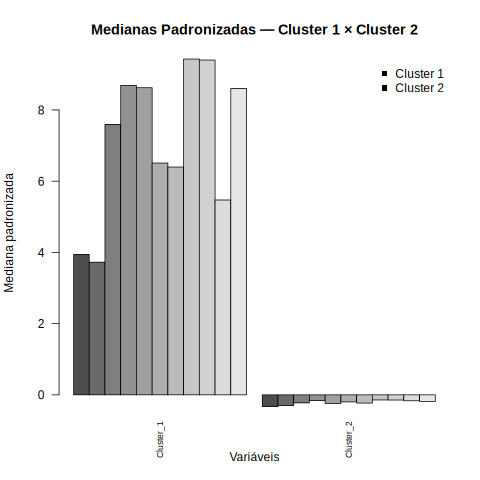

In [ ]:
%%R

# ============================================================
# GRÁFICO — CLUSTER 1 × CLUSTER 2
# NAS 11 VARIÁVEIS PRINCIPAIS
# ============================================================

# Medianas padronizadas das 11 variáveis
med_c1_11 <- apply(
  Xs[cl == 1, posicoes, drop = FALSE],
  2,
  median,
  na.rm = TRUE
)

med_c2_11 <- apply(
  Xs[cl == 2, posicoes, drop = FALSE],
  2,
  median,
  na.rm = TRUE
)

# Criar matriz para o gráfico
dados_grafico <- rbind(
  Cluster_1 = med_c1_11,
  Cluster_2 = med_c2_11
)

colnames(dados_grafico) <- nomes_variaveis

# Transpor para facilitar o gráfico
dados_grafico <- t(dados_grafico)

# Criar gráfico
barplot(
  dados_grafico,
  beside = TRUE,
  las = 2,
  cex.names = 0.7,
  main = "Medianas Padronizadas — Cluster 1 × Cluster 2",
  ylab = "Mediana padronizada",
  xlab = "Variáveis"
)

legend(
  "topright",
  legend = c("Cluster 1", "Cluster 2"),
  pch = 15,
  bty = "n"
)

In [ ]:
%%R

# ============================================================
# SALVAR GRÁFICO FINAL
# ============================================================

png(
  "/content/drive/MyDrive/Projeto_emails_ML/grafico_clusters_11_variaveis.png",
  width = 1600,
  height = 900,
  res = 150
)

barplot(
  dados_grafico,
  beside = TRUE,
  las = 2,
  cex.names = 0.8,
  main = "Medianas Padronizadas — Cluster 1 × Cluster 2",
  ylab = "Mediana padronizada",
  xlab = "Variáveis"
)

legend(
  "topright",
  legend = c("Cluster 1", "Cluster 2"),
  pch = 15,
  bty = "n"
)

dev.off()

cat("Gráfico salvo com sucesso.\n")

Gráfico salvo com sucesso.


In [ ]:
%%R

# ============================================================
# TABELA FINAL — 11 VARIÁVEIS PRINCIPAIS
# ============================================================

tabela_final <- data.frame(
  Variavel = nomes_variaveis,
  Mediana_C1 = med_c1_11,
  Mediana_C2 = med_c2_11,
  Diferenca = med_c1_11 - med_c2_11
)

tabela_final <- tabela_final[
  order(-abs(tabela_final$Diferenca)),
]

print(
  data.frame(
    Variavel = tabela_final$Variavel,
    Mediana_C1 = round(tabela_final$Mediana_C1, 3),
    Mediana_C2 = round(tabela_final$Mediana_C2, 3),
    Diferenca = round(tabela_final$Diferenca, 3)
  ),
  row.names = FALSE
)

             Variavel Mediana_C1 Mediana_C2 Diferenca
        word_freq_857      9.429     -0.143     9.572
        word_freq_415      9.401     -0.145     9.546
 word_freq_technology      8.625     -0.242     8.867
     word_freq_telnet      8.689     -0.161     8.850
     word_freq_direct      8.603     -0.185     8.788
       word_freq_labs      7.592     -0.225     7.817
         word_freq_85      6.509     -0.198     6.707
        word_freq_650      6.397     -0.232     6.629
        word_freq_lab      5.471     -0.167     5.638
         word_freq_hp      3.943     -0.329     4.272
        word_freq_hpl      3.726     -0.299     4.025


In [ ]:
%%R

cat("O objeto cl_star existe? ", exists("cl_star"), "\n")

if (exists("cl_star")) {
  cat("Quantidade de objetos:", length(cl_star), "\n\n")
  print(table(cl_star))
}

O objeto cl_star existe?  FALSE 


In [ ]:
%%R

source("double_kmeans_spambase.R")

cat("\nVerificação:\n")
cat("resultados existe? ", exists("resultados"), "\n")
cat("idx_star existe? ", exists("idx_star"), "\n")
cat("melhor existe? ", exists("melhor"), "\n")
cat("cl_star existe? ", exists("cl_star"), "\n")

n = 4601 objetos, J = 57 variáveis (1813 spam / 2788 não-spam)
K=2 H=1 | f=5742.00 (2.19% var.) | achada em 100/100 execuções | Sil=0.2961 | it=11 | f_drclust=NA
K=2 H=2 | f=17766.44 (6.78% var.) | achada em   7/100 execuções | Sil=0.6596 | it=29 | f_drclust=NA
K=3 H=1 | f=7841.28 (2.99% var.) | achada em 100/100 execuções | Sil=0.2515 | it=40 | f_drclust=NA
K=3 H=2 | f=22878.37 (8.73% var.) | achada em   7/100 execuções | Sil=0.2454 | it=51 | f_drclust=NA
K=3 H=3 | f=27817.15 (10.61% var.) | achada em  15/100 execuções | Sil=0.1426 | it=19 | f_drclust=NA
K=4 H=1 | f=8976.37 (3.42% var.) | achada em 100/100 execuções | Sil=0.0484 | it=38 | f_drclust=NA
K=4 H=2 | f=28892.02 (11.02% var.) | achada em  53/100 execuções | Sil=0.2428 | it=28 | f_drclust=NA
K=4 H=3 | f=33733.22 (12.87% var.) | achada em  18/100 execuções | Sil=0.1620 | it=41 | f_drclust=NA
K=4 H=4 | f=34987.65 (13.34% var.) | achada em   1/100 execuções | Sil=0.1585 | it=26 | f_drclust=NA

== Resumo por par (K,H) ==
 K H    

In [ ]:
%%R

# Salvar os rótulos da melhor solução da Q1
write.csv(
  data.frame(cluster = cl_star),
  "/content/cl_star.csv",
  row.names = FALSE
)

# Salvar também a matriz U
write.csv(
  melhor$U,
  "/content/U_K2_H2.csv",
  row.names = FALSE
)

cat("cl_star salvo:", length(cl_star), "objetos\n")
cat("U:", nrow(melhor$U), "x", ncol(melhor$U), "\n")

cl_star salvo: 4601 objetos
U: 4601 x 2 


# Questão 2 — Comparação dos Classificadores

Nesta questão serão consideradas duas versões do conjunto de dados **Spambase**:

1. **Spambase original:** variável resposta com as 2 classes originais.
2. **Spambase com agrupamento:** variável resposta definida pela partição de objetos obtida na Questão 1, com $K^*=2$.

Serão avaliados cinco classificadores:

1. Bayesiano Gaussiano;
2. Bayesiano baseado em k-vizinhos;
3. Bayesiano baseado em janela de Parzen;
4. Regressão Logística;
5. Voto Majoritário dos quatro classificadores anteriores.

A avaliação será realizada utilizando **validação cruzada estratificada 30 × 10-folds**.

# Classificador Bayesiano Gaussiano

O Classificador Bayesiano Gaussiano é um modelo de classificação baseado no Teorema de Bayes e na distribuição normal multivariada. Ele utiliza as características dos dados de treinamento para estimar a probabilidade de cada classe e, ao receber um novo exemplo, atribui-o à classe com maior probabilidade.

No conjunto Spambase original, o modelo foi utilizado para classificar os exemplos como spam ou não-spam. A avaliação foi realizada por meio de 30 × 10-folds de validação cruzada estratificada, totalizando 300 avaliações.

## 2.1 Preparação dos dados


In [ ]:
import pandas as pd
import numpy as np

# Carregar os clusters encontrados na Questão 1
cl_star = pd.read_csv("/content/cl_star.csv")["cluster"].to_numpy()

# Carregar também a matriz de pertinência U
U = pd.read_csv("/content/U_K2_H2.csv").to_numpy()

print("Quantidade de rótulos:", len(cl_star))
print("\nQuantidade de objetos em cada cluster:")
print(pd.Series(cl_star).value_counts().sort_index())

print("\nDimensão de U:", U.shape)

Quantidade de rótulos: 4601

Quantidade de objetos em cada cluster:
1      34
2    4567
Name: count, dtype: int64

Dimensão de U: (4601, 2)


In [ ]:
import pandas as pd

# Carregar o Spambase
df = pd.read_csv("data/spambase.data", header=None)

# 57 variáveis preditoras
X = df.iloc[:, :57].copy()

# Variável resposta original
y = df.iloc[:, 57].astype(int)

print("Dimensão de X:", X.shape)
print("\nDistribuição da variável original:")
print(y.value_counts().sort_index())

Dimensão de X: (4601, 57)

Distribuição da variável original:
57
0    2788
1    1813
Name: count, dtype: int64


In [ ]:
# Versão 1: variável resposta original do Spambase
y_original = y.astype(int)

# Versão 2: variável resposta usando os clusters da Questão 1
y_cluster = cl_star.astype(int)

print("=== VERSÃO ORIGINAL ===")
print(y_original.value_counts().sort_index())

print("\n=== VERSÃO DOS CLUSTERS ===")
print(pd.Series(y_cluster).value_counts().sort_index())

=== VERSÃO ORIGINAL ===
57
0    2788
1    1813
Name: count, dtype: int64

=== VERSÃO DOS CLUSTERS ===
1      34
2    4567
Name: count, dtype: int64


In [ ]:
# Verificar valores ausentes
print("Valores ausentes em X:", X.isna().sum().sum())

# Verificar valores infinitos
print("Valores infinitos em X:", np.isinf(X.to_numpy()).sum())

# Conferir dimensão final
print("X:", X.shape)
print("y_original:", y_original.shape)
print("y_cluster:", y_cluster.shape)

Valores ausentes em X: 0
Valores infinitos em X: 0
X: (4601, 57)
y_original: (4601,)
y_cluster: (4601,)


## 2.2 Validação cruzada estratificada — 30 × 10-folds


In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold

cv_externa = RepeatedStratifiedKFold(
    n_splits=10,
    n_repeats=30,
    random_state=42
)

print("Validação cruzada externa criada!")
print("Número de folds: 10")
print("Número de repetições: 30")
print("Total de avaliações:", cv_externa.get_n_splits())

Validação cruzada externa criada!
Número de folds: 10
Número de repetições: 30
Total de avaliações: 300


In [ ]:
# Pegar apenas a primeira divisão da validação cruzada
treino_idx, teste_idx = next(
    cv_externa.split(X, y_original)
)

print("Quantidade para treinamento:", len(treino_idx))
print("Quantidade para teste:", len(teste_idx))

print("\nDistribuição no treinamento:")
print(pd.Series(y_original.iloc[treino_idx]).value_counts().sort_index())

print("\nDistribuição no teste:")
print(pd.Series(y_original.iloc[teste_idx]).value_counts().sort_index())

Quantidade para treinamento: 4140
Quantidade para teste: 461

Distribuição no treinamento:
57
0    2509
1    1631
Name: count, dtype: int64

Distribuição no teste:
57
0    279
1    182
Name: count, dtype: int64


## 2.1 Preparação dos dados

Nesta etapa, foram preparados os dados da base **Spambase** para a realização dos experimentos da Questão 2.

A Questão 2 considera duas versões da base. A primeira mantém a **variável resposta original**, que possui duas classes: spam e não spam. A segunda utiliza uma nova variável resposta baseada na partição de objetos obtida na Questão 1, utilizando o número de clusters encontrado como \(K^*\). Como na Questão 1 foi obtido \(K^*=2\), a segunda versão da base também possui duas classes, correspondentes aos dois clusters encontrados.

A base possui **4601 exemplos e 57 atributos**. Os 57 primeiros atributos foram utilizados como variáveis de entrada \(X\), enquanto a última coluna foi utilizada como variável resposta original \(y\).

Também foi recuperada a classificação dos objetos obtida na Questão 1 para construir a variável `y_cluster`. Dessa forma, foram mantidas separadas as duas versões da variável resposta:

- `y_original`: classes originais da base Spambase;
- `y_cluster`: classes obtidas pelo agrupamento da Questão 1.

Antes de iniciar a avaliação dos classificadores, foram realizadas verificações para garantir que os dados estavam consistentes. Foram verificadas as dimensões da matriz de atributos, a quantidade de rótulos e a existência de valores ausentes ou infinitos. Não foram encontrados valores ausentes ou infinitos nos atributos.

### Distribuição das classes

Na variável resposta original, foram encontrados:

- **2788 exemplos da classe 0 (não spam);**
- **1813 exemplos da classe 1 (spam).**

Na variável baseada nos clusters da Questão 1, foram encontrados:

- **34 exemplos no cluster 1;**
- **4567 exemplos no cluster 2.**

Essa diferença na quantidade de exemplos entre as classes é importante para a avaliação dos classificadores. Por isso, o projeto solicita que seja utilizada **amostragem estratificada** durante a validação cruzada.

---

## 2.2 Validação cruzada estratificada

Para avaliar os classificadores, o projeto determina a utilização de uma validação cruzada **30 × 10-folds**.

A validação cruzada consiste em dividir os dados em diferentes partes para que o modelo possa ser treinado em uma parte dos dados e avaliado em outra. No caso de **10-folds**, a base é dividida em 10 partes. Em cada rodada, 9 partes são utilizadas para treinamento e 1 parte é utilizada para teste.

O processo é repetido até que cada uma das 10 partes tenha sido utilizada como conjunto de teste.

Além disso, o procedimento é repetido **30 vezes**, resultando em:

\[
30 \times 10 = 300
\]

avaliações diferentes.

Foi utilizada a versão **estratificada** da validação cruzada. Isso significa que, durante a divisão dos dados, procura-se manter aproximadamente a mesma proporção das classes presente na base original em cada conjunto de treinamento e teste. Essa estratégia é importante principalmente quando existe diferença na quantidade de exemplos entre as classes.

A validação cruzada foi configurada com 10 folds, 30 repetições e `random_state = 42`, permitindo reproduzir as mesmas divisões posteriormente.

Por fim, foi verificado o primeiro particionamento gerado. Foram obtidos **4140 exemplos para treinamento e 461 para teste**. A distribuição das classes também foi verificada nos dois conjuntos, confirmando que a estratificação estava sendo aplicada corretamente.

Assim, a etapa de preparação dos dados e criação da validação cruzada foi concluída. A próxima etapa consiste na implementação e avaliação do primeiro classificador solicitado no projeto: o **classificador Bayesiano Gaussiano**.

# MODELO 1 — Spambase original


In [ ]:
# Construção do treinmaneto do Bayesiano gaussiano
import numpy as np

def treinar_bayes_gaussiano(X_treino, y_treino):
    modelo = {}

    classes = np.unique(y_treino)
    n_total = len(y_treino)

    for classe in classes:
        # Seleciona somente os exemplos da classe atual
        X_classe = X_treino[y_treino == classe]

        # Probabilidade a priori da classe
        prior = len(X_classe) / n_total

        # Média dos 57 atributos
        media = np.mean(X_classe, axis=0)

        # Matriz de covariância de máxima verossimilhança
        cov = np.cov(
            X_classe,
            rowvar=False,
            bias=True
        )

        modelo[classe] = {
            "prior": prior,
            "media": media,
            "cov": cov
        }

    return modelo

In [ ]:
# Predição do classificador Bayesiano Gaussiano

import numpy as np

def prever_bayes_gaussiano(X_teste, modelo):
    predicoes = []

    for x in X_teste:

        probabilidades = {}

        for classe, parametros in modelo.items():

            prior = parametros["prior"]
            media = parametros["media"]
            cov = parametros["cov"]

            # Número de atributos
            d = len(media)

            # Inversa da matriz de covariância
            cov_inv = np.linalg.pinv(cov)

            # Determinante da matriz de covariância
            sinal, log_det = np.linalg.slogdet(cov)

            # Diferença entre o exemplo e a média
            diferenca = x - media

            # Parte quadrática da distribuição normal
            distancia = diferenca.T @ cov_inv @ diferenca

            # Log da densidade Gaussiana
            log_verossimilhanca = (
                -0.5 * d * np.log(2 * np.pi)
                -0.5 * log_det
                -0.5 * distancia
            )

            # Log da probabilidade conjunta
            log_probabilidade = (
                log_verossimilhanca + np.log(prior)
            )

            probabilidades[classe] = log_probabilidade

        # Escolhe a classe com maior probabilidade
        classe_predita = max(
            probabilidades,
            key=probabilidades.get
        )

        predicoes.append(classe_predita)

    return np.array(predicoes)

In [ ]:
# Separar os dados usando a primeira divisão da validação cruzada

X_treino = X.iloc[treino_idx].to_numpy()
X_teste = X.iloc[teste_idx].to_numpy()

y_treino = y_original.iloc[treino_idx].to_numpy()
y_teste = y_original.iloc[teste_idx].to_numpy()

print("X_treino:", X_treino.shape)
print("X_teste:", X_teste.shape)

print("y_treino:", y_treino.shape)
print("y_teste:", y_teste.shape)

X_treino: (4140, 57)
X_teste: (461, 57)
y_treino: (4140,)
y_teste: (461,)


In [ ]:
# Treinar o Bayesiano Gaussiano

modelo_bayes = treinar_bayes_gaussiano(
    X_treino,
    y_treino
)

print("Modelo treinado!")
print("Classes encontradas:", list(modelo_bayes.keys()))

Modelo treinado!
Classes encontradas: [np.int64(0), np.int64(1)]


In [ ]:
# Fazer previsões no conjunto de teste

y_pred = prever_bayes_gaussiano(
    X_teste,
    modelo_bayes
)

print("Primeiras 20 previsões:")
print(y_pred[:20])

print("\nPrimeiras 20 classes verdadeiras:")
print(y_teste[:20])

Primeiras 20 previsões:
[1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1]

Primeiras 20 classes verdadeiras:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [ ]:
# Fazer previsões no conjunto de teste

y_pred = prever_bayes_gaussiano(
    X_teste,
    modelo_bayes
)

print("Primeiras 20 previsões:")
print(y_pred[:20])

print("\nPrimeiras 20 classes verdadeiras:")
print(y_teste[:20])

Primeiras 20 previsões:
[1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1]

Primeiras 20 classes verdadeiras:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Acurácia
accuracy = accuracy_score(y_teste, y_pred)

# Taxa de erro
taxa_erro = 1 - accuracy

# Precisão
precisao = precision_score(y_teste, y_pred, zero_division=0)

# Cobertura (Recall)
cobertura = recall_score(y_teste, y_pred, zero_division=0)

# F-measure
f_measure = f1_score(y_teste, y_pred, zero_division=0)

print("=== MÉTRICAS — BAYESIANO GAUSSIANO ===")
print(f"Taxa de erro: {taxa_erro:.4f}")
print(f"Precisão:     {precisao:.4f}")
print(f"Cobertura:    {cobertura:.4f}")
print(f"F-measure:    {f_measure:.4f}")

=== MÉTRICAS — BAYESIANO GAUSSIANO ===
Taxa de erro: 0.1584
Precisão:     0.7319
Cobertura:    0.9451
F-measure:    0.8249


In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Dados do Modelo 1
X_dados = X.to_numpy()
y_dados = y_original.to_numpy()

# Número de repetições
n_repeticoes = 30

# Guardar as métricas das 300 avaliações
resultados_bayes = []

for repeticao in range(n_repeticoes):

    # 10 folds estratificados
    cv = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=42 + repeticao
    )

    for fold, (indice_treino, indice_teste) in enumerate(
        cv.split(X_dados, y_dados), start=1
    ):

        # Separar treinamento e teste
        X_treino_cv = X_dados[indice_treino]
        X_teste_cv = X_dados[indice_teste]

        y_treino_cv = y_dados[indice_treino]
        y_teste_cv = y_dados[indice_teste]

        # Treinar Bayesiano Gaussiano
        modelo = treinar_bayes_gaussiano(
            X_treino_cv,
            y_treino_cv
        )

        # Fazer previsões
        y_pred_cv = prever_bayes_gaussiano(
            X_teste_cv,
            modelo
        )

        # Métricas
        accuracy = accuracy_score(
            y_teste_cv,
            y_pred_cv
        )

        taxa_erro = 1 - accuracy

        precisao = precision_score(
            y_teste_cv,
            y_pred_cv,
            zero_division=0
        )

        cobertura = recall_score(
            y_teste_cv,
            y_pred_cv,
            zero_division=0
        )

        f_measure = f1_score(
            y_teste_cv,
            y_pred_cv,
            zero_division=0
        )

        # Guardar resultado
        resultados_bayes.append({
            "repeticao": repeticao + 1,
            "fold": fold,
            "taxa_erro": taxa_erro,
            "precisao": precisao,
            "cobertura": cobertura,
            "f_measure": f_measure
        })

print("Número de avaliações:", len(resultados_bayes))

Número de avaliações: 300


In [ ]:
import pandas as pd

df_resultados_bayes = pd.DataFrame(resultados_bayes)


df_resultados_bayes.head()

,repeticao,fold,taxa_erro,precisao,cobertura,f_measure
0,1,1,0.158351,0.731915,0.945055,0.824940
1,1,2,0.171739,0.713693,0.945055,0.813239
2,1,3,0.184783,0.693227,0.956044,0.803695
3,1,4,0.606522,0.393478,1.000000,0.564743
4,1,5,0.173913,0.702811,0.966851,0.813953


In [ ]:
medias_bayes = df_resultados_bayes[
    ["taxa_erro", "precisao", "cobertura", "f_measure"]
].mean()

print("=== ESTIMATIVA PONTUAL — BAYESIANO GAUSSIANO ===")
print(f"Taxa de erro: {medias_bayes['taxa_erro']:.4f}")
print(f"Precisão:     {medias_bayes['precisao']:.4f}")
print(f"Cobertura:    {medias_bayes['cobertura']:.4f}")
print(f"F-measure:    {medias_bayes['f_measure']:.4f}")

=== ESTIMATIVA PONTUAL — BAYESIANO GAUSSIANO ===
Taxa de erro: 0.2184
Precisão:     0.6781
Cobertura:    0.9560
F-measure:    0.7873


In [ ]:
import numpy as np

n = len(df_resultados_bayes)

media_erro = df_resultados_bayes["taxa_erro"].mean()
desvio_erro = df_resultados_bayes["taxa_erro"].std(ddof=1)

erro_padrao_erro = desvio_erro / np.sqrt(n)

margem_erro = 1.96 * erro_padrao_erro

limite_inferior_erro = media_erro - margem_erro
limite_superior_erro = media_erro + margem_erro

print("=== IC 95% — TAXA DE ERRO ===")
print(f"Estimativa pontual: {media_erro:.4f}")
print(f"Limite inferior:    {limite_inferior_erro:.4f}")
print(f"Limite superior:    {limite_superior_erro:.4f}")

=== IC 95% — TAXA DE ERRO ===
Estimativa pontual: 0.2184
Limite inferior:    0.2028
Limite superior:    0.2339


In [ ]:
metricas = ["precisao", "cobertura", "f_measure"]

print("=== IC 95% — BAYESIANO GAUSSIANO ===")

for metrica in metricas:
    valores = df_resultados_bayes[metrica]

    media = valores.mean()
    desvio = valores.std(ddof=1)
    erro_padrao = desvio / np.sqrt(len(valores))
    margem = 1.96 * erro_padrao

    limite_inferior = media - margem
    limite_superior = media + margem

    print(f"\n{metrica}:")
    print(f"  Estimativa pontual: {media:.4f}")
    print(f"  Limite inferior:    {limite_inferior:.4f}")
    print(f"  Limite superior:    {limite_superior:.4f}")

=== IC 95% — BAYESIANO GAUSSIANO ===

precisao:
  Estimativa pontual: 0.6781
  Limite inferior:    0.6665
  Limite superior:    0.6896

cobertura:
  Estimativa pontual: 0.9560
  Limite inferior:    0.9535
  Limite superior:    0.9585

f_measure:
  Estimativa pontual: 0.7873
  Limite inferior:    0.7783
  Limite superior:    0.7963


## Questão 2(b) — Bayesiano Gaussiano

Para a primeira versão da base Spambase, mantendo a variável resposta original com **2 classes**, foi realizada uma validação cruzada estratificada **30 × 10-folds**, totalizando **300 avaliações** do classificador Bayesiano Gaussiano.

Para cada avaliação foram calculadas as métricas **taxa de erro, precisão, cobertura (Recall) e F-measure**. A estimativa pontual foi obtida pela média dos resultados das 300 avaliações, e foram calculados intervalos de confiança de 95%.

Os resultados obtidos foram:

| Métrica      | Estimativa pontual |            IC 95% |
| ------------ | -----------------: | ----------------: |
| Taxa de erro |             0,2184 | [0,2028 ; 0,2339] |
| Precisão     |             0,6781 | [0,6665 ; 0,6896] |
| Cobertura    |             0,9560 | [0,9535 ; 0,9585] |
| F-measure    |             0,7873 | [0,7783 ; 0,7963] |

Em termos percentuais, a taxa de erro média foi de **21,84%**, enquanto a precisão, a cobertura e a F-measure apresentaram valores médios de **67,81%**, **95,60%** e **78,73%**, respectivamente.

Esta etapa corresponde à avaliação do **Bayesiano Gaussiano para a versão da Spambase com 2 classes originais**. Os resultados serão posteriormente comparados com os demais classificadores previstos na Questão 2.


In [ ]:
import pandas as pd

resultado_bayesiano = pd.DataFrame({
    "Classificador": ["Bayesiano Gaussiano"] * 4,
    "Metrica": [
        "Taxa de erro",
        "Precisao",
        "Cobertura",
        "F-measure"
    ],
    "Estimativa_pontual": [
        0.2184,
        0.6781,
        0.9560,
        0.7873
    ],
    "IC95_inferior": [
        0.2028,
        0.6665,
        0.9535,
        0.7783
    ],
    "IC95_superior": [
        0.2339,
        0.6896,
        0.9585,
        0.7963
    ]
})

nome_arquivo = "resultado_bayesiano_gaussiano.csv"

resultado_bayesiano.to_csv(
    nome_arquivo,
    index=False,
    encoding="utf-8-sig"
)

print(f"Arquivo criado: {nome_arquivo}")

Arquivo criado: resultado_bayesiano_gaussiano.csv


In [ ]:
from google.colab import files

files.download("resultado_bayesiano_gaussiano.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>